In [1]:

# ================================================================
# INSAT-3DS: RIFE + CMAM + CMCL — FULL IMAGE PREDICTION
#
# Input 0 : Frame at T
# Ground truth: Actual frame at T + 30 minutes
# Input 2 : Frame at T + 60 minutes
#
# NO PATCHES
# NO RESIZING
# NO PATCH OVERLAP OR BLENDING
#
# Metrics: MSE, PSNR, SSIM, MAE, RMSE, FSIM
# Dataset: INSAT-3DS HDF5, IMG_TIR1
# Mode: TEST ONLY
# ================================================================

import os
import sys
import re
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from PIL import Image
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity

# ================================================================
# 1. CONFIGURATION
# ================================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

INSAT_DATA_DIR = PROJECT_DIR / "Dataset"

RIFE_ROOT = PROJECT_DIR / "Research_RIFE"
MODEL_DIR = RIFE_ROOT / "model"
MODEL_FILE = MODEL_DIR / "RIFE_CMAM_CMCL.py"

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
    / "epoch_100.pth"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_RIFE_CMAM_CMCL_EPOCH100_FULL_IMAGE"
)

PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
GROUND_TRUTH_DIR = OUTPUT_DIR / "ground_truth"
INPUT_DIR = OUTPUT_DIR / "input_frames"

METRICS_CSV = OUTPUT_DIR / "per_triplet_metrics.csv"
SUMMARY_CSV = OUTPUT_DIR / "overall_metrics.csv"
FAILED_CSV = OUTPUT_DIR / "failed_triplets.csv"

HDF5_DATASET_NAME = "IMG_TIR1"

EXPECTED_INTERVAL_MINUTES = 30

# Process all valid triplets when MAX_TRIPLETS = 0.
MAX_TRIPLETS = 0

# Must match the normalization used during training.
# Verify this setting before interpreting the metrics.
NORMALIZATION_MODE = "shared_percentile"
PERCENTILE_LOW = 1.0
PERCENTILE_HIGH = 99.0

CMCL_WEIGHT = 0.01

# RIFE implementations often require dimensions divisible by 32.
# Pad the FULL image at the bottom/right, infer once, then crop
# back to the original dimensions. This does not resize the image.
PAD_MULTIPLE = 32

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
GROUND_TRUTH_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

try:
    import piq
    FSIM_AVAILABLE = True
except ImportError:
    piq = None
    FSIM_AVAILABLE = False
    print("WARNING: piq is unavailable. FSIM will be NaN.")

print("=" * 75)
print("INSAT-3DS — RIFE + CMAM + CMCL — FULL IMAGE EVALUATION")
print("=" * 75)
print("Project:", PROJECT_DIR)
print("Dataset:", INSAT_DATA_DIR)
print("Model:", MODEL_FILE)
print("Checkpoint:", CHECKPOINT_PATH)
print("Patch inference: DISABLED")
print("Image resizing: DISABLED")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

if not INSAT_DATA_DIR.exists():
    raise FileNotFoundError(INSAT_DATA_DIR)

if not MODEL_FILE.exists():
    raise FileNotFoundError(MODEL_FILE)

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(CHECKPOINT_PATH)

# ================================================================
# 2. IMPORT CUSTOM RIFE MODEL
# ================================================================

for dependency in (
    MODEL_DIR / "warplayer.py",
    MODEL_DIR / "IFNet.py",
):
    if not dependency.exists():
        raise FileNotFoundError(dependency)

rife_root_string = str(RIFE_ROOT.resolve())

if rife_root_string in sys.path:
    sys.path.remove(rife_root_string)

sys.path.insert(0, rife_root_string)

existing_model = sys.modules.get("model")

if existing_model is not None:
    existing_file = getattr(existing_model, "__file__", None)
    existing_paths = list(
        getattr(existing_model, "__path__", [])
    )

    correct_package = (
        existing_file is not None
        and Path(existing_file).resolve().parent
        == MODEL_DIR.resolve()
    ) or any(
        Path(p).resolve() == MODEL_DIR.resolve()
        for p in existing_paths
    )

    if not correct_package:
        for name in list(sys.modules):
            if name == "model" or name.startswith("model."):
                del sys.modules[name]

try:
    custom_module = importlib.import_module(
        "model.RIFE_CMAM_CMCL"
    )
except Exception as exc:
    raise ImportError(
        f"Failed to import custom model {MODEL_FILE}: {exc}"
    ) from exc

if not hasattr(custom_module, "Model"):
    raise AttributeError(
        "RIFE_CMAM_CMCL.py does not define Model."
    )

Model = custom_module.Model

print("Imported model:", custom_module.__file__)

# ================================================================
# 3. LOAD TRAINED CHECKPOINT
# ================================================================

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise RuntimeError("Unexpected checkpoint format.")

if "model_state_dict" not in checkpoint:
    raise KeyError(
        f"Checkpoint keys: {list(checkpoint.keys())}"
    )

print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))

network = None
network_name = None

if isinstance(model_cmcl, torch.nn.Module):
    network = model_cmcl
    network_name = "model wrapper"
else:
    for name in ("flownet", "network", "net", "model"):
        candidate = getattr(model_cmcl, name, None)

        if isinstance(candidate, torch.nn.Module):
            network = candidate
            network_name = name
            break

if network is None:
    raise RuntimeError(
        "Could not locate the neural network in Model."
    )

network.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

network.to(device)
network.eval()

if hasattr(model_cmcl, "eval"):
    try:
        model_cmcl.eval()
    except Exception:
        pass

del checkpoint

print("Checkpoint loaded successfully.")
print("Network:", network_name)
print("Evaluation mode enabled.")

# ================================================================
# 4. FIND HDF5 FILES AND BUILD TIMESTAMPED TRIPLETS
# ================================================================

def parse_insat_timestamp(path):
    match = re.search(
        r"(\d{2}[A-Z]{3}\d{4})_(\d{4})",
        path.name.upper()
    )

    if not match:
        return None

    date_text, time_text = match.groups()

    try:
        return datetime.strptime(
            date_text + time_text,
            "%d%b%Y%H%M"
        )
    except ValueError:
        return None


all_h5 = sorted(
    list(INSAT_DATA_DIR.rglob("*.h5"))
    + list(INSAT_DATA_DIR.rglob("*.hdf5"))
)

if not all_h5:
    raise FileNotFoundError(
        f"No HDF5 files found in {INSAT_DATA_DIR}"
    )

# Deduplicate identical paths.
all_h5 = list(dict.fromkeys(all_h5))

timestamped_files = []

for path in all_h5:
    timestamp = parse_insat_timestamp(path)

    if timestamp is not None:
        timestamped_files.append((timestamp, path))

# If multiple files share a timestamp, do not arbitrarily select
# one. Such duplicates must be checked before building triplets.
timestamped_files.sort(key=lambda item: (item[0], str(item[1])))

if len(timestamped_files) < 3:
    raise RuntimeError(
        "Fewer than three timestamped HDF5 files were found."
    )

timestamp_counts = pd.Series(
    [t for t, _ in timestamped_files]
).value_counts()

duplicate_times = set(
    timestamp_counts[timestamp_counts > 1].index
)

if duplicate_times:
    print(
        "WARNING:",
        len(duplicate_times),
        "timestamps have multiple HDF5 files."
    )
    print(
        "Verify that the selected files correspond to the same "
        "INSAT product and IMG_TIR1 channel."
    )

triplets = []

for i in range(len(timestamped_files) - 2):
    t0, p0 = timestamped_files[i]
    t1, p1 = timestamped_files[i + 1]
    t2, p2 = timestamped_files[i + 2]

    delta01 = (t1 - t0).total_seconds() / 60
    delta12 = (t2 - t1).total_seconds() / 60

    if (
        delta01 == EXPECTED_INTERVAL_MINUTES
        and delta12 == EXPECTED_INTERVAL_MINUTES
    ):
        triplets.append({
            "timestamp0": t0,
            "timestamp1": t1,
            "timestamp2": t2,
            "path0": p0,
            "path1": p1,
            "path2": p2,
        })

if not triplets:
    raise RuntimeError(
        "No valid 30-minute triplets found. "
        "Check timestamps and missing frames."
    )

if MAX_TRIPLETS > 0:
    triplets = triplets[:MAX_TRIPLETS]

print("HDF5 files:", len(all_h5))
print("Timestamped files:", len(timestamped_files))
print("Valid triplets:", len(triplets))

for item in triplets[:3]:
    print(
        item["timestamp0"],
        "->",
        item["timestamp1"],
        "->",
        item["timestamp2"]
    )

# ================================================================
# 5. LOAD IMG_TIR1
# ================================================================

def find_hdf5_dataset(h5_file, dataset_name):
    if dataset_name in h5_file:
        return h5_file[dataset_name][()]

    found = []

    def visitor(name, obj):
        if (
            isinstance(obj, h5py.Dataset)
            and name.split("/")[-1].upper()
            == dataset_name.upper()
        ):
            found.append(name)

    h5_file.visititems(visitor)

    if not found:
        raise KeyError(
            f"{dataset_name} was not found in {h5_file.filename}"
        )

    if len(found) > 1:
        raise KeyError(
            f"Multiple datasets named {dataset_name} in "
            f"{h5_file.filename}: {found}"
        )

    return h5_file[found[0]][()]


def load_insat_frame(path):
    with h5py.File(path, "r") as h5:
        arr = find_hdf5_dataset(
            h5, HDF5_DATASET_NAME
        )

    arr = np.squeeze(np.asarray(arr))

    if arr.ndim != 2:
        raise ValueError(
            f"Expected a 2D image in {path}, got {arr.shape}"
        )

    arr = arr.astype(np.float32)
    arr[~np.isfinite(arr)] = np.nan

    if not np.isfinite(arr).any():
        raise ValueError(f"No valid pixels in {path}")

    return arr


# ================================================================
# 6. NORMALIZE ALL THREE FRAMES USING ONE SHARED SCALE
# ================================================================

def normalize_triplet(raw0, raw1, raw2):
    valid0 = np.isfinite(raw0)
    valid1 = np.isfinite(raw1)
    valid2 = np.isfinite(raw2)

    values = np.concatenate([
        raw0[valid0],
        raw1[valid1],
        raw2[valid2]
    ])

    if values.size == 0:
        raise ValueError("No valid pixel values.")

    if NORMALIZATION_MODE == "shared_percentile":
        lo = float(np.percentile(values, PERCENTILE_LOW))
        hi = float(np.percentile(values, PERCENTILE_HIGH))

    elif NORMALIZATION_MODE == "minmax":
        lo = float(values.min())
        hi = float(values.max())

    else:
        raise ValueError(
            f"Unsupported normalization: {NORMALIZATION_MODE}"
        )

    if not np.isfinite(lo + hi) or hi <= lo:
        raise ValueError(f"Invalid scale: {lo}, {hi}")

    def scale(arr):
        valid = np.isfinite(arr)
        out = np.zeros(arr.shape, dtype=np.float32)
        out[valid] = (arr[valid] - lo) / (hi - lo)
        return np.clip(out, 0.0, 1.0)

    return (
        scale(raw0),
        scale(raw1),
        scale(raw2),
        valid0,
        valid1,
        valid2,
        lo,
        hi
    )


# ================================================================
# 7. FULL-IMAGE PREDICTION — NO PATCHING
# ================================================================

def extract_prediction(output, expected_hw):
    if isinstance(output, dict):
        preferred = (
            "prediction", "pred", "output", "merged", "frame"
        )

        for key in preferred:
            if key in output:
                try:
                    return extract_prediction(
                        output[key], expected_hw
                    )
                except ValueError:
                    pass

        candidates = list(output.values())

    elif isinstance(output, (tuple, list)):
        candidates = list(output)

    else:
        candidates = [output]

    tensors = [
        item for item in candidates
        if torch.is_tensor(item)
        and item.ndim == 4
        and item.shape[1] in (1, 3)
        and tuple(item.shape[-2:]) == tuple(expected_hw)
    ]

    if not tensors:
        shapes = [
            tuple(item.shape)
            for item in candidates
            if torch.is_tensor(item)
        ]

        raise ValueError(
            f"No prediction with size {expected_hw}; "
            f"output shapes: {shapes}"
        )

    return tensors[-1]


def predict_full_image(img0_np, img2_np):
    """
    Predict one complete image in a single model inference.

    Input:
        Two normalized grayscale arrays of shape [H, W].

    Output:
        One normalized grayscale array of the same shape.

    Only boundary padding to the model's required dimensions is
    used. No resizing, tiling, patching, or blending is performed.
    """

    if img0_np.shape != img2_np.shape:
        raise ValueError("Input frame shapes do not match.")

    original_h, original_w = img0_np.shape

    # The model expects 3-channel inputs.
    img0 = torch.from_numpy(
        np.ascontiguousarray(img0_np)
    )[None, None].repeat(1, 3, 1, 1)

    img2 = torch.from_numpy(
        np.ascontiguousarray(img2_np)
    )[None, None].repeat(1, 3, 1, 1)

    # Pad only bottom/right to satisfy common RIFE architectures.
    pad_h = (
        (PAD_MULTIPLE - original_h % PAD_MULTIPLE)
        % PAD_MULTIPLE
    )
    pad_w = (
        (PAD_MULTIPLE - original_w % PAD_MULTIPLE)
        % PAD_MULTIPLE
    )

    if pad_h or pad_w:
        # Replication padding also works for very small dimensions.
        img0 = F.pad(
            img0, (0, pad_w, 0, pad_h), mode="replicate"
        )
        img2 = F.pad(
            img2, (0, pad_w, 0, pad_h), mode="replicate"
        )

    print(
        f"Full input: {original_h} x {original_w}; "
        f"model input: {img0.shape[-2]} x {img0.shape[-1]}"
    )

    img0 = img0.to(device)
    img2 = img2.to(device)

    concatenated = torch.cat([img0, img2], dim=1)
    expected_hw = img0.shape[-2:]

    errors = []
    methods = []

    if callable(getattr(model_cmcl, "inference", None)):
        methods.append(
            ("wrapper.inference", model_cmcl.inference)
        )

    if callable(getattr(network, "inference", None)):
        methods.append(
            ("network.inference", network.inference)
        )

    try:
        with torch.inference_mode():
            output = None

            for method_name, method in methods:
                for args in ((img0, img2), (concatenated,)):
                    try:
                        candidate = method(*args)
                        candidate = extract_prediction(
                            candidate, expected_hw
                        )
                        output = candidate
                        print("Inference API:", method_name)
                        break
                    except Exception as exc:
                        errors.append(
                            f"{method_name}: "
                            f"{type(exc).__name__}: {exc}"
                        )

                if output is not None:
                    break

            if output is None:
                try:
                    output = network(concatenated)
                    output = extract_prediction(
                        output, expected_hw
                    )
                    print("Inference API: network.forward")
                except Exception as exc:
                    errors.append(
                        f"network.forward: "
                        f"{type(exc).__name__}: {exc}"
                    )

            if output is None:
                raise RuntimeError(
                    "All model inference methods failed:\n"
                    + "\n".join(errors)
                )

            if not torch.isfinite(output).all():
                raise ValueError(
                    "Model prediction contains NaN or infinity."
                )

            if output.shape[1] == 1:
                pred = output
            else:
                # The three output channels represent the same
                # grayscale satellite image.
                pred = output.mean(dim=1, keepdim=True)

            # Remove only the boundary padding.
            pred = pred[:, :, :original_h, :original_w]

            if tuple(pred.shape[-2:]) != (original_h, original_w):
                raise RuntimeError(
                    f"Output size mismatch: {pred.shape}"
                )

            pred = pred.float().clamp(0.0, 1.0)

            return (
                pred[0, 0]
                .cpu()
                .numpy()
                .astype(np.float32)
            )

    except torch.cuda.OutOfMemoryError as exc:
        if device.type == "cuda":
            torch.cuda.empty_cache()

        raise RuntimeError(
            "CUDA out of memory during full-image inference. "
            "This run intentionally does not fall back to patches. "
            "Use a GPU with more available memory or a model "
            "architecture designed for full-resolution inference."
        ) from exc


# ================================================================
# 8. METRICS
# ================================================================

def calculate_metrics(pred, gt, valid_mask):
    valid = (
        valid_mask
        & np.isfinite(pred)
        & np.isfinite(gt)
    )

    if valid.sum() < 16:
        raise ValueError("Too few valid pixels for evaluation.")

    p = np.clip(pred[valid], 0.0, 1.0).astype(np.float64)
    g = np.clip(gt[valid], 0.0, 1.0).astype(np.float64)

    mse = float(np.mean((p - g) ** 2))
    mae = float(np.mean(np.abs(p - g)))
    rmse = float(np.sqrt(mse))

    psnr = (
        float("inf")
        if mse == 0
        else float(10.0 * np.log10(1.0 / mse))
    )

    # Fill invalid GT regions with GT so they do not create
    # artificial structural differences in the SSIM/FSIM images.
    gt_full = np.clip(
        np.nan_to_num(gt, nan=0.0), 0.0, 1.0
    ).astype(np.float32)

    pred_full = np.clip(
        np.nan_to_num(pred, nan=0.0), 0.0, 1.0
    ).astype(np.float32)

    pred_full = np.where(valid_mask, pred_full, gt_full)

    min_side = min(gt_full.shape)

    if min_side < 3:
        ssim = float("nan")
    else:
        win_size = min(7, min_side)
        if win_size % 2 == 0:
            win_size -= 1

        ssim = float(
            structural_similarity(
                gt_full,
                pred_full,
                data_range=1.0,
                win_size=win_size
            )
        )

    fsim = float("nan")

    if FSIM_AVAILABLE:
        try:
            # Full-frame FSIM may consume substantial memory.
            # Use CPU to avoid allocating another full image and
            # its intermediate feature maps on the inference GPU.
            gt_t = torch.from_numpy(
                np.repeat(gt_full[None, None], 3, axis=1).copy()
            )

            pred_t = torch.from_numpy(
                np.repeat(pred_full[None, None], 3, axis=1).copy()
            )

            with torch.inference_mode():
                fsim = float(
                    piq.fsim(
                        pred_t,
                        gt_t,
                        data_range=1.0,
                        reduction="mean"
                    ).item()
                )

        except Exception as exc:
            warnings.warn(f"Full-image FSIM failed: {exc}")

    return {
        "MSE": mse,
        "PSNR_dB": psnr,
        "SSIM": ssim,
        "MAE": mae,
        "RMSE": rmse,
        "FSIM": fsim,
        "valid_pixels": int(valid.sum()),
        "total_pixels": int(valid_mask.size)
    }


# ================================================================
# 9. PROCESS ALL VALID TRIPLETS
# ================================================================

metric_rows = []
failed_rows = []
global_start = time.time()


def save_grayscale(path, image):
    output = np.nan_to_num(
        image, nan=0.0, posinf=0.0, neginf=0.0
    )

    output = np.round(
        np.clip(output, 0.0, 1.0) * 255
    ).astype(np.uint8)

    Image.fromarray(output).save(path)


for idx, triplet in enumerate(
    tqdm(triplets, desc="Full-image INSAT evaluation")
):
    try:
        p0 = triplet["path0"]
        p1 = triplet["path1"]
        p2 = triplet["path2"]

        print(f"\nTriplet {idx + 1}/{len(triplets)}")
        print("Input T      :", p0.name)
        print("Ground truth :", p1.name)
        print("Input T+60   :", p2.name)

        raw0 = load_insat_frame(p0)
        raw1 = load_insat_frame(p1)
        raw2 = load_insat_frame(p2)

        if not (raw0.shape == raw1.shape == raw2.shape):
            raise ValueError(
                f"Frame sizes differ: "
                f"{raw0.shape}, {raw1.shape}, {raw2.shape}"
            )

        original_shape = raw0.shape

        (
            img0, gt, img2,
            valid0, valid_gt, valid2,
            scale_low, scale_high
        ) = normalize_triplet(raw0, raw1, raw2)

        # Invalid input pixels are filled with normalized zero.
        img0 = np.where(valid0, img0, 0.0).astype(np.float32)
        img2 = np.where(valid2, img2, 0.0).astype(np.float32)

        print("Original image size:", original_shape)
        print(
            f"Shared normalization: {scale_low:.6f} to "
            f"{scale_high:.6f}"
        )

        # One forward inference over the complete image.
        pred = predict_full_image(img0, img2)

        if pred.shape != original_shape:
            raise ValueError(
                f"Prediction shape {pred.shape} != "
                f"original shape {original_shape}"
            )

        metrics = calculate_metrics(pred, gt, valid_gt)

        stamp = triplet["timestamp1"].strftime("%Y%m%d_%H%M")

        pred_path = (
            PREDICTIONS_DIR / f"predicted_{stamp}.png"
        )
        gt_path = (
            GROUND_TRUTH_DIR / f"ground_truth_{stamp}.png"
        )
        input0_path = INPUT_DIR / f"input_{stamp}_T.png"
        input2_path = INPUT_DIR / f"input_{stamp}_Tplus60.png"

        save_grayscale(pred_path, pred)
        save_grayscale(gt_path, gt)
        save_grayscale(input0_path, img0)
        save_grayscale(input2_path, img2)

        row = {
            "triplet_id": idx,
            "timestamp_input0": triplet["timestamp0"].isoformat(),
            "timestamp_target": triplet["timestamp1"].isoformat(),
            "timestamp_input2": triplet["timestamp2"].isoformat(),
            "original_height": original_shape[0],
            "original_width": original_shape[1],
            "input0_path": str(p0),
            "ground_truth_path": str(p1),
            "input2_path": str(p2),
            "prediction_path": str(pred_path),
            "saved_ground_truth_path": str(gt_path),
            "normalization_low": scale_low,
            "normalization_high": scale_high,
            **metrics
        }

        metric_rows.append(row)

        print(
            f"MSE={metrics['MSE']:.8f} | "
            f"PSNR={metrics['PSNR_dB']:.4f} dB | "
            f"SSIM={metrics['SSIM']:.6f} | "
            f"MAE={metrics['MAE']:.8f} | "
            f"RMSE={metrics['RMSE']:.8f} | "
            f"FSIM={metrics['FSIM']:.6f}"
        )

        # Save results after every completed triplet.
        pd.DataFrame(metric_rows).to_csv(
            METRICS_CSV, index=False
        )

        del raw0, raw1, raw2
        del img0, gt, img2, pred

        if device.type == "cuda":
            torch.cuda.empty_cache()

    except Exception as exc:
        print(
            f"FAILED triplet {idx}: "
            f"{type(exc).__name__}: {exc}"
        )

        failed_rows.append({
            "triplet_id": idx,
            "input0": str(triplet["path0"]),
            "target": str(triplet["path1"]),
            "input2": str(triplet["path2"]),
            "error": f"{type(exc).__name__}: {exc}"
        })

        pd.DataFrame(failed_rows).to_csv(
            FAILED_CSV, index=False
        )

# ================================================================
# 10. OVERALL METRICS
# ================================================================

if not metric_rows:
    raise RuntimeError(
        "No triplets completed. Check the errors and failed CSV."
    )

results_df = pd.DataFrame(metric_rows)
results_df.to_csv(METRICS_CSV, index=False)

# Aggregate pixel-wise metrics by valid pixel count.
weights = results_df["valid_pixels"].to_numpy(np.float64)
mse_values = results_df["MSE"].to_numpy(np.float64)
mae_values = results_df["MAE"].to_numpy(np.float64)

mse_ok = (
    np.isfinite(weights)
    & (weights > 0)
    & np.isfinite(mse_values)
)

mae_ok = (
    np.isfinite(weights)
    & (weights > 0)
    & np.isfinite(mae_values)
)

if not mse_ok.any() or not mae_ok.any():
    raise RuntimeError("No valid pixel metrics for aggregation.")

global_mse = float(
    np.average(mse_values[mse_ok], weights=weights[mse_ok])
)

global_mae = float(
    np.average(mae_values[mae_ok], weights=weights[mae_ok])
)

global_rmse = float(np.sqrt(global_mse))

global_psnr = (
    float("inf")
    if global_mse == 0
    else float(10.0 * np.log10(1.0 / global_mse))
)

def weighted_average(column):
    values = results_df[column].to_numpy(np.float64)

    ok = (
        np.isfinite(values)
        & np.isfinite(weights)
        & (weights > 0)
    )

    if not ok.any():
        return float("nan")

    return float(np.average(values[ok], weights=weights[ok]))


weighted_ssim = weighted_average("SSIM")
weighted_fsim = weighted_average("FSIM")

overall = pd.DataFrame([{
    "model": "RIFE + CMAM + CMCL",
    "checkpoint": str(CHECKPOINT_PATH),
    "dataset": "INSAT-3DS IMG_TIR1",
    "inference_mode": "FULL_IMAGE_NO_PATCHES",
    "target_interval_minutes": EXPECTED_INTERVAL_MINUTES,
    "endpoint_separation_minutes": 60,
    "successful_triplets": len(metric_rows),
    "failed_triplets": len(failed_rows),
    "total_valid_pixels": int(weights.sum()),
    "Global_MSE": global_mse,
    "Global_PSNR_dB": global_psnr,
    "Global_MAE": global_mae,
    "Global_RMSE": global_rmse,
    "Pixel_Weighted_SSIM": weighted_ssim,
    "Pixel_Weighted_FSIM": weighted_fsim,
    "elapsed_seconds": time.time() - global_start
}])

overall.to_csv(SUMMARY_CSV, index=False)

if failed_rows:
    pd.DataFrame(failed_rows).to_csv(
        FAILED_CSV, index=False
    )

print("\n" + "=" * 75)
print("FINAL RESULTS — FULL-IMAGE INSAT EVALUATION")
print("=" * 75)
print("Successful triplets:", len(metric_rows))
print("Failed triplets:", len(failed_rows))
print(f"Global MSE: {global_mse:.10f}")
print(f"Global PSNR: {global_psnr:.6f} dB")
print(f"Global MAE: {global_mae:.10f}")
print(f"Global RMSE: {global_rmse:.10f}")
print(f"Weighted SSIM: {weighted_ssim:.8f}")
print(f"Weighted FSIM: {weighted_fsim:.8f}")
print(f"Elapsed seconds: {time.time() - global_start:.1f}")

print("\nOUTPUT FILES")
print("Per-triplet metrics:", METRICS_CSV)
print("Overall metrics:", SUMMARY_CSV)
print("Predicted images:", PREDICTIONS_DIR)
print("Ground-truth images:", GROUND_TRUTH_DIR)
print("Input images:", INPUT_DIR)

if failed_rows:
    print("Failed triplets:", FAILED_CSV)

print("\nFull-image evaluation finished.")


INSAT-3DS — RIFE + CMAM + CMCL — FULL IMAGE EVALUATION
Project: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation
Dataset: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Dataset
Model: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM_CMCL.py
Checkpoint: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_100.pth
Patch inference: DISABLED
Image resizing: DISABLED
Device: cuda
GPU: NVIDIA H200 NVL
Imported model: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM_CMCL.py
Checkpoint epoch: 100
Checkpoint loaded successfully.
Network: flownet
Evaluation mode enabled.
HDF5 files: 426
Timestamped files: 426
Valid triplets: 416
2026-07-07 00:00:00 -> 2026-07-07 00:30:00 -> 2026-07-07 01:00:00
2026-07-07 00:30:00 -> 2026-07-07 01:00:00 -> 2026-07-07 01:30:00
2026-07-07 01:00:00 -> 2026-07-07 01:30:00 -> 2026-07-07 02:00:00


Full-image INSAT evaluation:   0%|          | 0/416 [00:00<?, ?it/s]


Triplet 1/416
Input T      : 3SIMG_07JUL2026_0000_L1B_STD_V01R00_B3.h5
Ground truth : 3SIMG_07JUL2026_0030_L1B_STD_V01R00_B3.h5
Input T+60   : 3SIMG_07JUL2026_0100_L1B_STD_V01R00_B3.h5
Original image size: (2816, 2805)
Shared normalization: 505.000000 to 1023.000000
Full input: 2816 x 2805; model input: 2816 x 2816
Inference API: wrapper.inference
MSE=0.00133547 | PSNR=28.7437 dB | SSIM=0.800949 | MAE=0.01844238 | RMSE=0.03654406 | FSIM=0.989860

Triplet 2/416
Input T      : 3SIMG_07JUL2026_0030_L1B_STD_V01R00_B3.h5
Ground truth : 3SIMG_07JUL2026_0100_L1B_STD_V01R00_B3.h5
Input T+60   : 3SIMG_07JUL2026_0130_L1B_STD_V01R00_B3.h5
Original image size: (2816, 2805)
Shared normalization: 503.000000 to 1023.000000
Full input: 2816 x 2805; model input: 2816 x 2816
Inference API: wrapper.inference
MSE=0.00132002 | PSNR=28.7942 dB | SSIM=0.803114 | MAE=0.01839040 | RMSE=0.03633210 | FSIM=0.990204

Triplet 3/416
Input T      : 3SIMG_07JUL2026_0100_L1B_STD_V01R00_B3.h5
Ground truth : 3SIMG_07JUL

Input T shape: (2816, 2805)
Input T+60 shape: (2816, 2805)
Predicted shape: (2816, 2805)
Ground truth shape: (2816, 2805)


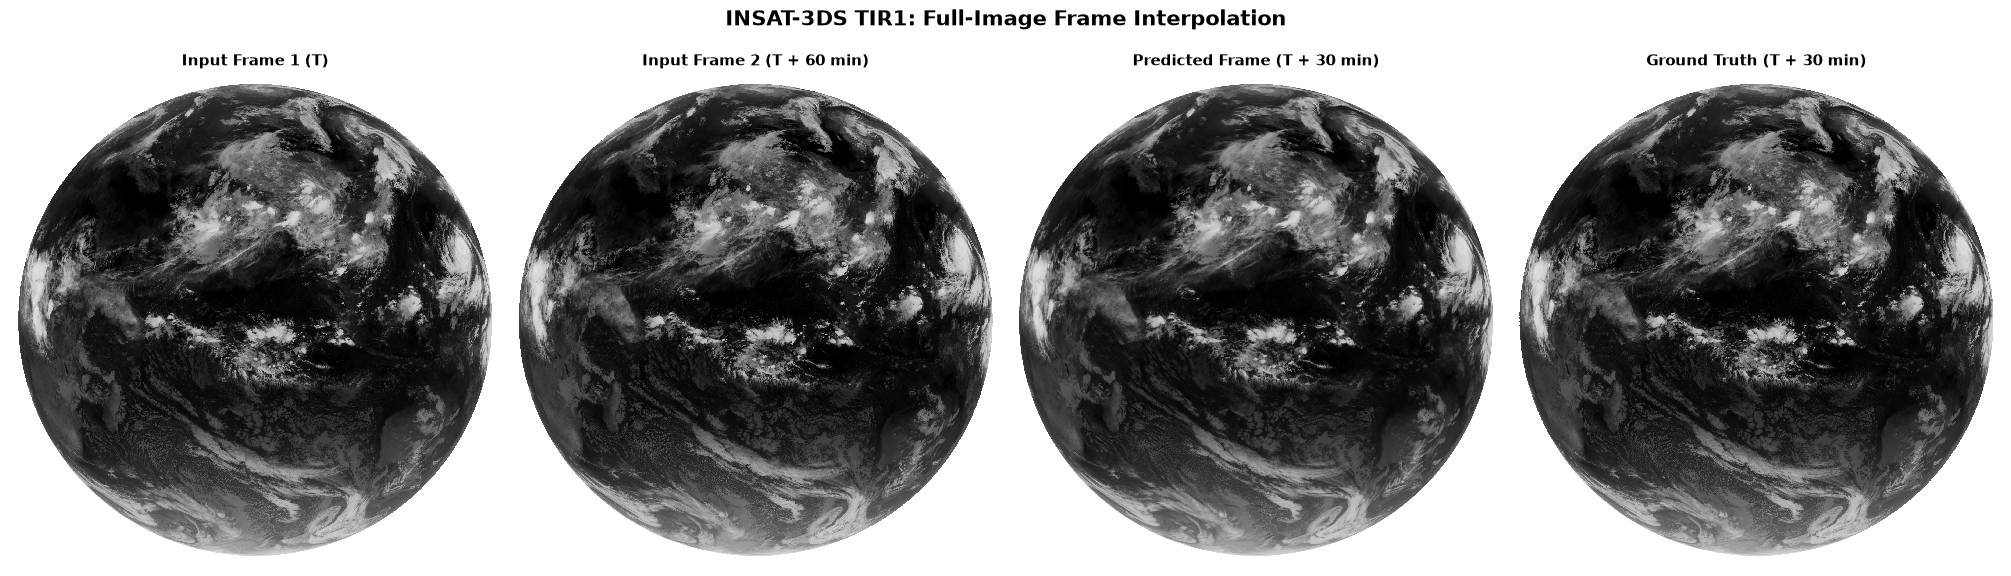

Saved PNG: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_RIFE_CMAM_CMCL_EPOCH100_FULL_IMAGE/visualizations/INSAT_full_image_comparison_20260707_0030.png
Saved PDF: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_RIFE_CMAM_CMCL_EPOCH100_FULL_IMAGE/visualizations/INSAT_full_image_comparison_20260707_0030.pdf


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_RIFE_CMAM_CMCL_EPOCH100_FULL_IMAGE"
)

METRICS_CSV = OUTPUT_DIR / "per_triplet_metrics.csv"

# Select a triplet:
# 0 = first successful triplet
# 1 = second successful triplet, etc.
TRIPLET_INDEX = 0

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        f"Metrics CSV not found: {METRICS_CSV}"
    )

df = pd.read_csv(METRICS_CSV)

if df.empty:
    raise ValueError("The metrics CSV contains no results.")

if TRIPLET_INDEX < 0 or TRIPLET_INDEX >= len(df):
    raise IndexError(
        f"Choose an index between 0 and {len(df) - 1}"
    )

row = df.iloc[TRIPLET_INDEX]


def load_grayscale(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Image not found: {path}"
        )

    image = np.asarray(
        Image.open(path).convert("L"),
        dtype=np.float32
    )

    return image / 255.0


# Load the four saved images.
input_t = load_grayscale(
    OUTPUT_DIR / "input_frames"
    / f"input_{pd.to_datetime(row['timestamp_target']).strftime('%Y%m%d_%H%M')}_T.png"
)

input_t60 = load_grayscale(
    OUTPUT_DIR / "input_frames"
    / f"input_{pd.to_datetime(row['timestamp_target']).strftime('%Y%m%d_%H%M')}_Tplus60.png"
)

predicted = load_grayscale(row["prediction_path"])

ground_truth = load_grayscale(
    row["saved_ground_truth_path"]
)

# Confirm image dimensions.
print("Input T shape:", input_t.shape)
print("Input T+60 shape:", input_t60.shape)
print("Predicted shape:", predicted.shape)
print("Ground truth shape:", ground_truth.shape)

if not (
    input_t.shape
    == input_t60.shape
    == predicted.shape
    == ground_truth.shape
):
    raise ValueError(
        "The four saved images do not have matching dimensions."
    )

# Use the same display scale for all images.
fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 6),
    constrained_layout=True
)

images = [
    input_t,
    input_t60,
    predicted,
    ground_truth
]

titles = [
    "Input Frame 1 (T)",
    "Input Frame 2 (T + 60 min)",
    "Predicted Frame (T + 30 min)",
    "Ground Truth (T + 30 min)"
]

for ax, image, title in zip(axes, images, titles):
    im = ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.axis("off")

fig.suptitle(
    "INSAT-3DS TIR1: Full-Image Frame Interpolation",
    fontsize=15,
    fontweight="bold"
)

PLOT_DIR = OUTPUT_DIR / "visualizations"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

timestamp = pd.to_datetime(
    row["timestamp_target"]
).strftime("%Y%m%d_%H%M")

png_path = (
    PLOT_DIR
    / f"INSAT_full_image_comparison_{timestamp}.png"
)

pdf_path = (
    PLOT_DIR
    / f"INSAT_full_image_comparison_{timestamp}.pdf"
)

plt.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)


In [6]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "INSAT3DS_RIFE_CMAM_CMCL_EPOCH100_FULL_IMAGE"
)

METRICS_CSV = OUTPUT_DIR / "per_triplet_metrics.csv"

TRIPLET_ID = 199

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        f"CSV file not found: {METRICS_CSV}"
    )

df = pd.read_csv(METRICS_CSV)

# Check required column
if "triplet_id" not in df.columns:
    raise KeyError("triplet_id column not found.")

# Select the required triplet
selected = df.loc[
    df["triplet_id"] == TRIPLET_ID
]

if selected.empty:
    raise ValueError(
        f"Triplet ID {TRIPLET_ID} not found."
    )

row = selected.iloc[0]

# Display all evaluation metrics
metrics = {
    "MSE": "MSE",
    "PSNR (dB)": "PSNR_dB",
    "SSIM": "SSIM",
    "MAE": "MAE",
    "RMSE": "RMSE",
    "FSIM": "FSIM"
}

print("\n" + "=" * 60)
print(" INSAT-3DS TIR1 - RIFE ENHANCED MODEL")
print(f" TRIPLET ID: {TRIPLET_ID}")
print("=" * 60)

print("\nTIMESTAMP INFORMATION")
print("-" * 60)
print("Input Frame T       :", row["timestamp_input0"])
print("Ground Truth T+30   :", row["timestamp_target"])
print("Input Frame T+60    :", row["timestamp_input2"])

print("\nIMAGE INFORMATION")
print("-" * 60)
print("Image Height        :", row["original_height"])
print("Image Width         :", row["original_width"])
print("Valid Pixels        :", int(row["valid_pixels"]))
print("Total Pixels        :", int(row["total_pixels"]))
print("Normalization Low   :", row["normalization_low"])
print("Normalization High  :", row["normalization_high"])

print("\nEVALUATION METRICS")
print("-" * 60)

for label, column in metrics.items():
    print(f"{label:<20}: {row[column]:.10f}")

print("=" * 60)

print("\nPREDICTION IMAGE:")
print(row["prediction_path"])

print("\nGROUND TRUTH IMAGE:")
print(row["saved_ground_truth_path"])

# Save selected metrics into a separate CSV
result = selected[
    ["triplet_id", "timestamp_target",
     "MSE", "PSNR_dB", "SSIM", "MAE", "RMSE", "FSIM"]
]

save_path = OUTPUT_DIR / f"triplet_{TRIPLET_ID}_metrics.csv"

result.to_csv(save_path, index=False)

print("\nMetrics saved successfully:")
print(save_path)



 INSAT-3DS TIR1 - RIFE ENHANCED MODEL
 TRIPLET ID: 199

TIMESTAMP INFORMATION
------------------------------------------------------------
Input Frame T       : 2026-07-11T09:00:00
Ground Truth T+30   : 2026-07-11T09:30:00
Input Frame T+60    : 2026-07-11T10:00:00

IMAGE INFORMATION
------------------------------------------------------------
Image Height        : 2816
Image Width         : 2805
Valid Pixels        : 7898880
Total Pixels        : 7898880
Normalization Low   : 296.0
Normalization High  : 1023.0

EVALUATION METRICS
------------------------------------------------------------
MSE                 : 0.0007530598
PSNR (dB)           : 31.2317054209
SSIM                : 0.8642032100
MAE                 : 0.0130323310
RMSE                : 0.0274419349
FSIM                : 0.9934158325

PREDICTION IMAGE:
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/results/INSAT3DS_RIFE_CMAM_CMCL_EPOCH100_FULL_IMAGE/predictions/predicted_20260711_0930.png

GROUND TRUTH IMAGE:
/home